# 9. Ajuste de hiperparámetros

Toda metaheurística tiene hiperparámetros, como el tamaño de la población, las probabilidades de cruce y mutación, la temperatura inicial y la tasa de enfriamiento, o el peso de la feromona frente al de la heurística, y su desempeño depende de ellos tanto como del diseño del algoritmo. Ajustarlos a mano, probando valores uno por uno, es lento y deja sin explorar las interacciones entre hiperparámetros. Este capítulo plantea el ajuste como un problema de optimización en sí mismo y lo resuelve con la biblioteca Optuna. El caso de estudio es el problema del agente viajero (TSP, *traveling salesman problem*) con 20 ciudades, y se ajustan los hiperparámetros de cuatro metaheurísticas: un algoritmo genético construido con DEAP, el recocido simulado (*simulated annealing*), la optimización por colonia de hormigas (*ant colony optimization*) y GRASP (*greedy randomized adaptive search procedure*).

## Optuna

Optuna organiza el ajuste alrededor de tres objetos. La función objetivo recibe una prueba (`trial`), le pide valores para cada hiperparámetro con métodos como `suggest_int` y `suggest_float`, ejecuta el algoritmo con esos valores y devuelve una medida de desempeño, que aquí es la longitud del mejor recorrido encontrado. Cada llamada a esa función es una prueba. El estudio (`study`) guarda todas las pruebas y decide qué valores proponer en la siguiente.

El espacio de búsqueda queda definido dentro de la propia función objetivo: un rango de enteros con paso, un rango de reales con paso o un rango de reales en escala logarítmica (`log=True`), útil cuando el valor puede variar en varios órdenes de magnitud, como una temperatura.

Para proponer valores, los estudios de este capítulo usan el muestreador TPE (*tree-structured Parzen estimator*). Las primeras pruebas se sortean al azar. Después, TPE separa las pruebas hechas en un grupo de buenas y otro de malas según su valor objetivo, estima una densidad $\ell(x)$ para los hiperparámetros del grupo bueno y otra $g(x)$ para los del grupo malo, y propone el $x$ que hace grande el cociente $\ell(x)/g(x)$, es decir, valores que se parecen a los que funcionaron y poco a los que no. La semilla del muestreador está fija, así que la secuencia de pruebas es reproducible.

Un detalle de diseño merece atención desde el comienzo. Cada prueba ejecuta la metaheurística una sola vez, con una semilla fija (123), para que dos configuraciones se comparen sobre la misma secuencia aleatoria. El precio es que el mejor valor de un estudio describe una corrida y no el desempeño esperado del algoritmo; el capítulo 10 muestra cómo comparar con varias corridas.

## Configuración

En Colab hay que instalar Optuna y DEAP; basta descomentar las líneas de la celda siguiente.

In [1]:
# Instalación de bibliotecas (descomentar en Colab si no están instaladas)
# !pip install optuna
# !pip install deap

In [2]:
import math
import random
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
# Optuna importa tqdm, que advierte si no encuentra ipywidgets; la advertencia no afecta el cuaderno
warnings.filterwarnings("ignore", message="IProgress not found")
import optuna

# Para Algoritmos Genéticos con DEAP
from deap import base, creator, tools, algorithms

# Optuna informa cada prueba en la salida; se deja solo en advertencias para que la salida se pueda leer
optuna.logging.set_verbosity(optuna.logging.WARNING)
# Las gráficas de Optuna con matplotlib se marcan como experimentales
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

print("Optuna y DEAP listos (si la instalación fue exitosa).")

Optuna y DEAP listos (si la instalación fue exitosa).


Las gráficas de Optuna se generan con `optuna.visualization.matplotlib`, que produce figuras estáticas. La función siguiente solo traduce sus títulos, ejes y leyendas.

In [3]:
def traducir_grafica(ax, titulo, xlabel=None, ylabel=None):
    """Pone en español el título, los ejes y la leyenda de una gráfica de Optuna."""
    traducciones = {"Objective Value": "Valor objetivo", "Best Value": "Mejor valor",
                    "Infeasible Trial": "Prueba infactible"}
    for posicion in ("left", "right"):   # algunas gráficas ponen el título a la izquierda
        ax.set_title("", loc=posicion)
    ax.set_title(titulo)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    leyenda = ax.get_legend()
    if leyenda is not None:
        for texto in leyenda.get_texts():
            texto.set_text(traducciones.get(texto.get_text(), texto.get_text()))

## El problema del agente viajero

Una solución del TSP es una permutación de las ciudades, y su costo es la longitud del recorrido cerrado que las visita en ese orden y vuelve a la primera. Se necesitan tres funciones auxiliares:

1. `generate_cities(num_cities)` crea un conjunto de ciudades con coordenadas $(x, y)$ aleatorias en un cuadrado de 100 por 100.
2. `calculate_distance_matrix(cities)` calcula la matriz de distancias euclidianas entre todos los pares de ciudades.
3. `calculate_tour_length(tour, distance_matrix)` calcula la longitud total de un recorrido.

La instancia tiene 20 ciudades, un número pequeño para que los estudios terminen rápido.

In [4]:
def generate_cities(num_cities, width=100, height=100, seed=None):
    """Genera un conjunto de ciudades con coordenadas (x, y) aleatorias."""
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
    cities = []
    for _ in range(num_cities):
        cities.append((random.uniform(0, width), random.uniform(0, height)))
    return cities

def calculate_distance_matrix(cities):
    """Calcula la matriz de distancias euclidianas entre todas las pares de ciudades."""
    num_cities = len(cities)
    distance_matrix = np.zeros((num_cities, num_cities))
    for i in range(num_cities):
        for j in range(i + 1, num_cities):
            dist = math.sqrt((cities[i][0] - cities[j][0])**2 +
                             (cities[i][1] - cities[j][1])**2)
            distance_matrix[i][j] = dist
            distance_matrix[j][i] = dist
    return distance_matrix

def calculate_tour_length(tour, distance_matrix):
    """Calcula la longitud total de un recorrido (tour) dado.
    Un tour es una lista de índices de ciudades en orden.
    """
    total_distance = 0
    num_cities = len(tour)
    for i in range(num_cities):
        from_city = tour[i]
        to_city = tour[(i + 1) % num_cities] # Regresa a la ciudad de origen
        total_distance += distance_matrix[from_city][to_city]
    return total_distance

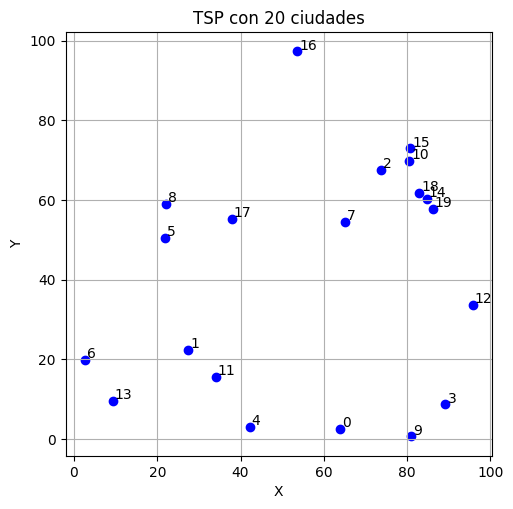

Generadas 20 ciudades y su matriz de distancias.
Ejemplo de distancia entre ciudad 0 y 1: 41.48


In [5]:
# --- Ejemplo de uso de las funciones del TSP ---
NUM_CITIES_GLOBAL = 20 # Usaremos un número pequeño para que las optimizaciones sean rápidas
CITIES_GLOBAL = generate_cities(NUM_CITIES_GLOBAL, seed=42)
DISTANCE_MATRIX_GLOBAL = calculate_distance_matrix(CITIES_GLOBAL)

# Visualizar las ciudades
plt.figure(figsize=(5.5, 5.5))
x_coords = [city[0] for city in CITIES_GLOBAL]
y_coords = [city[1] for city in CITIES_GLOBAL]
plt.scatter(x_coords, y_coords, c='blue')
for i, city in enumerate(CITIES_GLOBAL):
   plt.annotate(str(i), (city[0] + 0.5, city[1] + 0.5))
plt.title(f"TSP con {NUM_CITIES_GLOBAL} ciudades")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.show()

print(f"Generadas {NUM_CITIES_GLOBAL} ciudades y su matriz de distancias.")
print(f"Ejemplo de distancia entre ciudad 0 y 1: {DISTANCE_MATRIX_GLOBAL[0,1]:.2f}")

## Algoritmo genético con DEAP

DEAP (*Distributed Evolutionary Algorithms in Python*) es una biblioteca para construir algoritmos evolutivos a partir de piezas que se registran en una caja de herramientas (`toolbox`). Los algoritmos genéticos son también la base de los algoritmos meméticos del capítulo 7.

### Implementación

Cada individuo es una permutación de los índices de las ciudades, y su aptitud es la longitud del recorrido, que se minimiza (de ahí el peso $-1$ en `FitnessMin`). Los operadores son el cruce ordenado (`cxOrdered`), que produce hijos que siguen siendo permutaciones; la mutación por barajado de índices (`mutShuffleIndexes`), que intercambia cada posición con otra al azar con probabilidad `indpb`, y la selección por torneo (`selTournament`). El ciclo es el algoritmo `eaSimple` de DEAP, que en cada generación selecciona, cruza con probabilidad `cxpb` y muta con probabilidad `mutpb` cada individuo.

La función `run_ga_tsp` vuelve a registrar la selección y la mutación con los hiperparámetros de la prueba. El hiperparámetro `mutpb` cumple dos papeles, porque es la probabilidad de mutar un individuo y, dividido por el número de ciudades, es también la probabilidad `indpb` de alterar cada posición del individuo que muta.

In [6]:
# Configuración de DEAP
# Queremos minimizar la longitud del tour
creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
# Un individuo es una lista de índices de ciudades (una permutación)
creator.create("Individual", list, fitness=creator.FitnessMin)

toolbox = base.Toolbox()

# Generador de atributos: una permutación de los índices de las ciudades
# Asegurarse de que NUM_CITIES_GLOBAL está definido
INDICES_CIUDADES = list(range(NUM_CITIES_GLOBAL))
toolbox.register("indices", random.sample, INDICES_CIUDADES, NUM_CITIES_GLOBAL)

# Inicializador de individuos y población
toolbox.register("individual", tools.initIterate, creator.Individual, toolbox.indices)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

# Función de evaluación
def evalTSP(individual):
    """Función de evaluación para el TSP: calcula la longitud del tour."""
    return calculate_tour_length(individual, DISTANCE_MATRIX_GLOBAL),

# Registro de operadores genéticos
toolbox.register("evaluate", evalTSP)
toolbox.register("mate", tools.cxOrdered) # Crossover ordenado, bueno para permutaciones
toolbox.register("mutate", tools.mutShuffleIndexes, indpb=0.05) # Mutación por barajado de índices
toolbox.register("select", tools.selTournament, tournsize=3) # Selección por torneo

In [7]:
def run_ga_tsp(population_size, cxpb, mutpb, ngen, tournsize, seed=None):
    """Ejecuta el Algoritmo Genético para el TSP con los hiperparámetros dados."""
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    # Actualizar tournsize en el toolbox si es necesario
    toolbox.unregister("select") # Desregistrar el anterior para evitar errores
    toolbox.register("select", tools.selTournament, tournsize=int(tournsize))
    # Actualizar indpb para la mutación
    toolbox.unregister("mutate")
    toolbox.register("mutate", tools.mutShuffleIndexes, indpb=float(mutpb/NUM_CITIES_GLOBAL)) # indpb es por gen

    pop = toolbox.population(n=int(population_size))

    # Guardar estadísticas (opcional, pero útil)
    stats = tools.Statistics(lambda ind: ind.fitness.values)
    stats.register("avg", np.mean)
    stats.register("std", np.std)
    stats.register("min", np.min)
    stats.register("max", np.max)

    # El algoritmo simple de DEAP es suficiente para este ejemplo
    # Para problemas más complejos, se podría usar algorithms.eaMuPlusLambda o similar
    final_pop, logbook = algorithms.eaSimple(pop, toolbox,
                                             cxpb=float(cxpb),
                                             mutpb=float(mutpb), # Probabilidad de mutar un individuo
                                             ngen=int(ngen),
                                             stats=stats,
                                             verbose=False) # Poner a True para ver progreso

    best_individual = tools.selBest(final_pop, 1)[0]
    best_fitness = best_individual.fitness.values[0]
    return best_fitness, best_individual, logbook

### Espacio de búsqueda y estudio

El estudio explora cinco hiperparámetros:

| Hiperparámetro | Rango | Paso |
|---|---|---|
| `population_size` | 50 a 200 | 10 |
| `cxpb` | 0,50 a 0,95 | 0,05 |
| `mutpb_ind` (probabilidad de mutar un individuo) | 0,05 a 0,30 | 0,05 |
| `ngen` (generaciones) | 50 a 200 | 10 |
| `tournsize` | 2 a 7 | 1 |

Se hacen 50 pruebas, con un límite de 300 segundos.

In [8]:
def objective_ga(trial):
    """Función objetivo para Optuna para optimizar los hiperparámetros del GA."""
    # Definir el espacio de búsqueda de hiperparámetros
    population_size = trial.suggest_int("population_size", 50, 200, step=10)
    cxpb = trial.suggest_float("cxpb", 0.5, 0.95, step=0.05)
    mutpb_ind = trial.suggest_float("mutpb_ind", 0.05, 0.3, step=0.05) # Probabilidad de mutar un individuo
    ngen = trial.suggest_int("ngen", 50, 200, step=10)
    tournsize = trial.suggest_int("tournsize", 2, 7)

    # Ejecutar el GA con los hiperparámetros sugeridos
    # Usamos una semilla fija dentro de la función objetivo para Optuna
    # para que la evaluación de un conjunto de hiperparámetros sea más consistente.
    # Sin embargo, para la evaluación final del mejor conjunto de hiperparámetros,
    # se deberían realizar múltiples ejecuciones con diferentes semillas.
    best_fitness, _, _ = run_ga_tsp(population_size, cxpb, mutpb_ind, ngen, tournsize, seed=123)

    return best_fitness # Optuna intentará minimizar este valor

In [9]:
# --- Ejecutar la optimización con Optuna para GA ---
random.seed(42)
np.random.seed(42)
print("--- Iniciando Optimización de Hiperparámetros para GA con Optuna ---")
inicio = time.time()
study_ga = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study_ga.optimize(objective_ga, n_trials=50, timeout=300) # n_trials y timeout bajos para demo
print(f"\nOptimización GA completada en {time.time() - inicio:.1f} s ({len(study_ga.trials)} pruebas).")
print("Mejor valor (longitud de tour):", round(study_ga.best_value, 2))
print("Mejores hiperparámetros para GA:", study_ga.best_params)

--- Iniciando Optimización de Hiperparámetros para GA con Optuna ---



Optimización GA completada en 16.3 s (50 pruebas).
Mejor valor (longitud de tour): 352.32
Mejores hiperparámetros para GA: {'population_size': 160, 'cxpb': 0.6, 'mutpb_ind': 0.2, 'ngen': 150, 'tournsize': 2}


Optuna trae varias gráficas para leer un estudio. La historia de la optimización muestra el valor de cada prueba y el mejor valor acumulado. La gráfica de cortes (*slice plot*) muestra, para cada hiperparámetro, el valor objetivo de cada prueba frente al valor que tomó ese hiperparámetro, con el color indicando el número de la prueba. La gráfica de importancias estima cuánto de la variación del valor objetivo se debe a cada hiperparámetro, con el evaluador por omisión de Optuna.

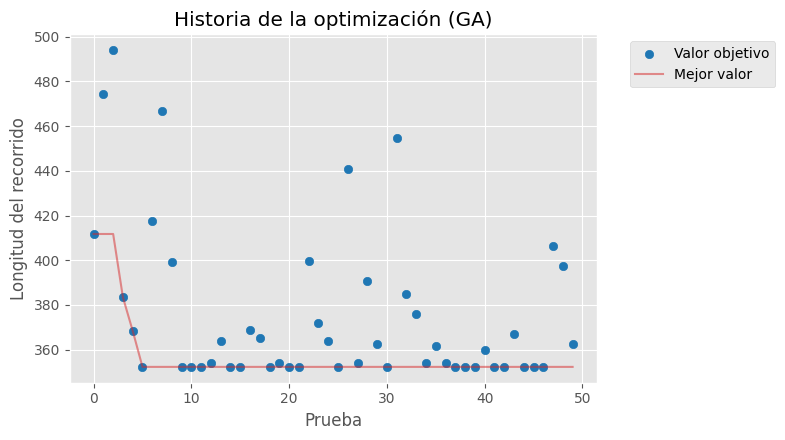

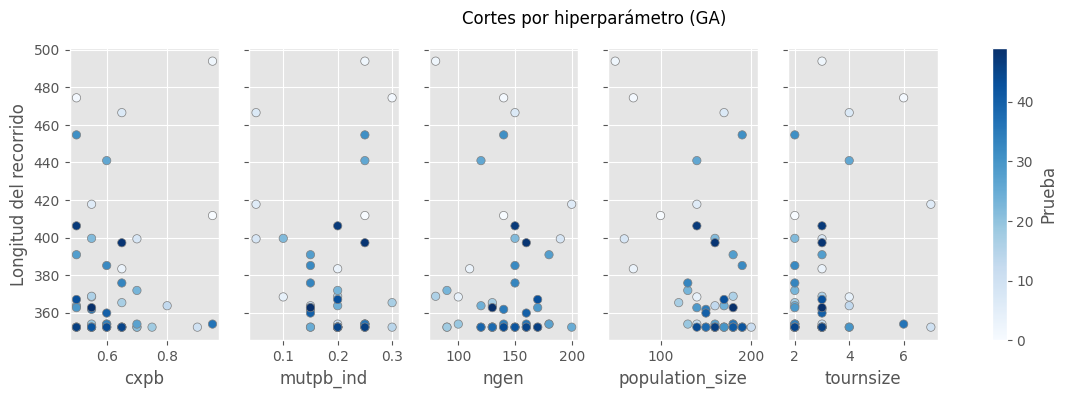

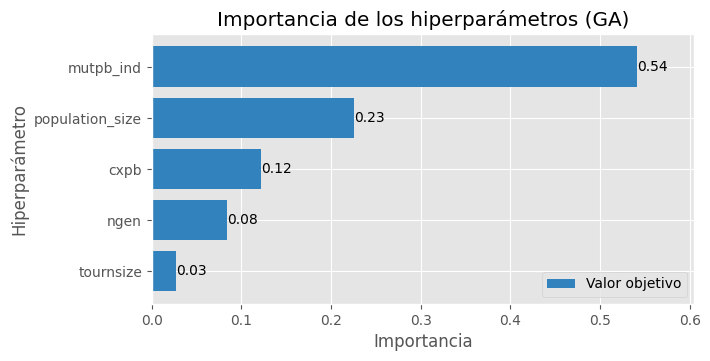

In [10]:
# Visualizaciones de Optuna
ax = optuna.visualization.matplotlib.plot_optimization_history(study_ga)
traducir_grafica(ax, "Historia de la optimización (GA)", "Prueba", "Longitud del recorrido")
ax.figure.set_size_inches(8, 4.5)
plt.show()

axs = optuna.visualization.matplotlib.plot_slice(study_ga)
axs[0].set_ylabel("Longitud del recorrido")
axs[0].figure.suptitle("Cortes por hiperparámetro (GA)")
axs[0].figure.axes[-1].set_ylabel("Prueba")  # barra de color
axs[0].figure.set_size_inches(14, 3.8)
plt.show()

ax = optuna.visualization.matplotlib.plot_param_importances(study_ga)
traducir_grafica(ax, "Importancia de los hiperparámetros (GA)", "Importancia", "Hiperparámetro")
ax.figure.set_size_inches(7, 3.5)
plt.show()

Las primeras pruebas, que TPE sortea al azar, dan recorridos muy dispares. Después, el estudio llega pronto al mejor valor y buena parte de las pruebas siguientes se concentra cerca de él, aunque TPE sigue proponiendo de vez en cuando configuraciones alejadas, que vuelven a dar recorridos largos. En la gráfica de cortes se ve, por ejemplo, que las pruebas con probabilidad de mutación de 0,05 quedan todas lejos del mejor valor, y la gráfica de importancias señala esa probabilidad como el hiperparámetro que más pesa, seguida del tamaño de la población. Varias configuraciones distintas alcanzan el mismo mejor recorrido, de modo que los «mejores hiperparámetros» que imprime Optuna corresponden solo a una de ellas, la que quedó con el valor más bajo por diferencias en el último decimal.

## Recocido simulado

El recocido simulado se estudió en el capítulo 2. Esta versión para el TSP parte de un recorrido aleatorio y genera cada vecino intercambiando las posiciones de dos ciudades elegidas al azar (aunque el comentario de la función lo llama 2-opt, el movimiento es un intercambio). Un vecino que acorta el recorrido se acepta siempre, y uno que lo alarga se acepta con probabilidad

$$
P(\text{aceptar}) = \exp\!\left(\frac{E_{\text{actual}} - E_{\text{vecino}}}{T}\right),
$$

donde $E$ es la longitud del recorrido y $T$ la temperatura. En cada temperatura se hacen `max_iterations_per_temp` intentos; luego la temperatura baja geométricamente, $T \leftarrow \alpha\, T$, con la tasa de enfriamiento $\alpha$, y el proceso termina cuando $T$ llega a la temperatura mínima.

In [11]:
def create_initial_solution_sa(num_cities, seed=None):
    """Crea una solución inicial aleatoria (un tour)."""
    if seed is not None:
        random.seed(seed)
    tour = list(range(num_cities))
    random.shuffle(tour)
    return tour

def get_neighbor_solution_sa(current_tour):
    """Obtiene una solución vecina intercambiando dos ciudades aleatorias (2-opt simple)."""
    neighbor_tour = current_tour[:]
    idx1, idx2 = random.sample(range(len(neighbor_tour)), 2)
    neighbor_tour[idx1], neighbor_tour[idx2] = neighbor_tour[idx2], neighbor_tour[idx1]
    return neighbor_tour

def acceptance_probability(current_energy, neighbor_energy, temperature):
    """Calcula la probabilidad de aceptación de una peor solución."""
    if neighbor_energy < current_energy:
        return 1.0
    if temperature == 0: # Evitar división por cero
        return 0.0
    return math.exp((current_energy - neighbor_energy) / temperature)

def run_simulated_annealing_tsp(initial_temp, cooling_rate, min_temp, max_iterations_per_temp, seed=None):
    """Ejecuta Simulated Annealing para el TSP."""
    if seed is not None:
        random.seed(seed)

    num_cities = NUM_CITIES_GLOBAL
    current_solution = create_initial_solution_sa(num_cities, seed=seed)
    current_energy = calculate_tour_length(current_solution, DISTANCE_MATRIX_GLOBAL)

    best_solution = current_solution[:]
    best_energy = current_energy

    temperature = initial_temp

    while temperature > min_temp:
        for _ in range(int(max_iterations_per_temp)):
            neighbor_solution = get_neighbor_solution_sa(current_solution)
            neighbor_energy = calculate_tour_length(neighbor_solution, DISTANCE_MATRIX_GLOBAL)

            if acceptance_probability(current_energy, neighbor_energy, temperature) > random.random():
                current_solution = neighbor_solution[:]
                current_energy = neighbor_energy

                if current_energy < best_energy:
                    best_solution = current_solution[:]
                    best_energy = current_energy

        temperature *= cooling_rate
        if temperature == 0 and min_temp > 0: # Asegurar que no se quede en 0 si min_temp es > 0
            temperature = min_temp / 2 # Forzar salida si cooling_rate es muy agresivo

    return best_energy, best_solution

### Espacio de búsqueda y estudio

| Hiperparámetro | Rango | Escala o paso |
|---|---|---|
| `initial_temp` | 100 a 10 000 | logarítmica |
| `cooling_rate` | 0,850 a 0,999 | 0,001 |
| `min_temp` | 0,01 a 1 | logarítmica |
| `max_iterations_per_temp` | 50 a 500 | 50 |

El número de pasos de enfriamiento crece muy rápido cuando la tasa se acerca a 1, porque es aproximadamente $\ln(T_{\min}/T_0)/\ln \alpha$. Con $\alpha = 0{,}999$ una sola prueba puede durar varios segundos, así que este estudio hace 30 pruebas.

In [12]:
def objective_sa(trial):
    """Función objetivo para Optuna para optimizar los hiperparámetros del SA."""
    initial_temp = trial.suggest_float("initial_temp", 100, 10000, log=True)
    cooling_rate = trial.suggest_float("cooling_rate", 0.85, 0.999, step=0.001)
    min_temp = trial.suggest_float("min_temp", 0.01, 1.0, log=True)
    max_iterations_per_temp = trial.suggest_int("max_iterations_per_temp", 50, 500, step=50)

    best_fitness, _ = run_simulated_annealing_tsp(initial_temp, cooling_rate, min_temp, max_iterations_per_temp, seed=123)
    return best_fitness

--- Iniciando Optimización de Hiperparámetros para SA con Optuna ---



Optimización SA completada en 36.9 s (30 pruebas).
Mejor valor (longitud de tour): 352.32
Mejores hiperparámetros para SA: {'initial_temp': 134.92834268013254, 'cooling_rate': 0.992, 'min_temp': 0.8536189862866826, 'max_iterations_per_temp': 450}


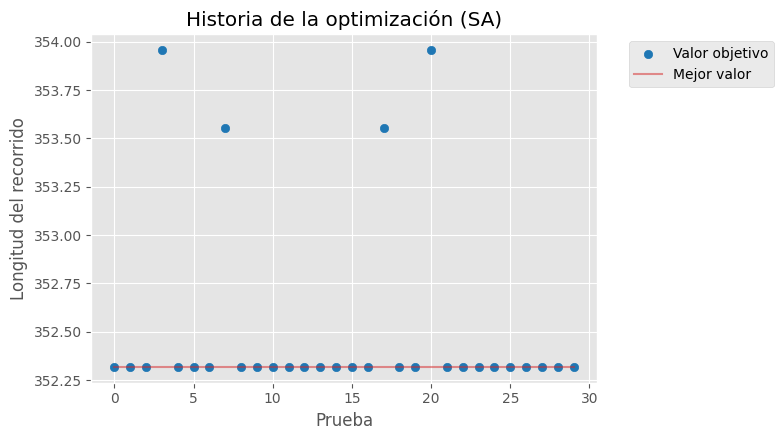

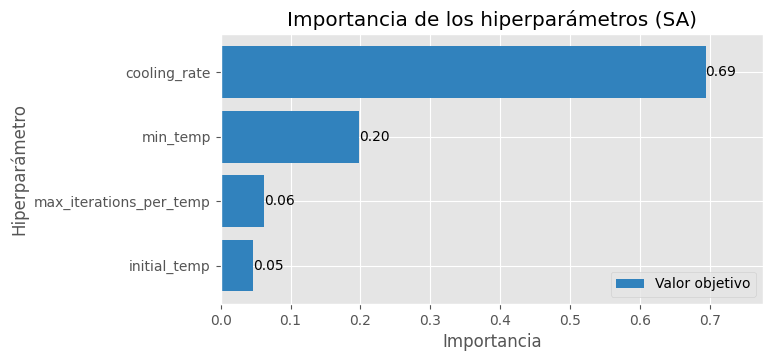

In [13]:
# --- Ejecutar la optimización con Optuna para SA ---
random.seed(42)
np.random.seed(42)
print("--- Iniciando Optimización de Hiperparámetros para SA con Optuna ---")
inicio = time.time()
study_sa = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study_sa.optimize(objective_sa, n_trials=30, timeout=300) # 30 pruebas (75 en el script original)

print(f"\nOptimización SA completada en {time.time() - inicio:.1f} s ({len(study_sa.trials)} pruebas).")
print("Mejor valor (longitud de tour):", round(study_sa.best_value, 2))
print("Mejores hiperparámetros para SA:", study_sa.best_params)

ax = optuna.visualization.matplotlib.plot_optimization_history(study_sa)
traducir_grafica(ax, "Historia de la optimización (SA)", "Prueba", "Longitud del recorrido")
ax.figure.set_size_inches(8, 4.5)
plt.show()

ax = optuna.visualization.matplotlib.plot_param_importances(study_sa)
traducir_grafica(ax, "Importancia de los hiperparámetros (SA)", "Importancia", "Hiperparámetro")
ax.figure.set_size_inches(7, 3.5)
plt.show()

En este estudio casi todas las configuraciones llevan al mismo recorrido, que es también el mejor que encontró el algoritmo genético, y la historia de la optimización queda casi plana. Cuando la gran mayoría de las pruebas empata, la gráfica de importancias reparte la importancia a partir de las pocas pruebas que no llegan al mejor valor y no debe leerse como una propiedad del recocido simulado. En una situación así, entre las configuraciones empatadas conviene preferir las más baratas, y aquí el costo cambia mucho de una a otra, porque las tasas de enfriamiento cercanas a 1 multiplican el número de temperaturas.

## Colonia de hormigas

La colonia de hormigas se estudió en el capítulo 4; esta es una versión simplificada para ilustrar el ajuste. Cada hormiga parte de una ciudad al azar y construye un recorrido eligiendo la siguiente ciudad $j$, entre las no visitadas $\mathcal{N}_i$, con probabilidad

$$
p_{ij} = \frac{\tau_{ij}^{\alpha}\, \eta_{ij}^{\beta}}{\sum_{l \in \mathcal{N}_i} \tau_{il}^{\alpha}\, \eta_{il}^{\beta}}, \qquad \eta_{ij} = \frac{1}{d_{ij}},
$$

donde $\tau_{ij}$ es la feromona del arco, $\eta_{ij}$ la información heurística, y $\alpha$ y $\beta$ ponderan una y otra. La feromona empieza en 0,1 en todos los arcos. Al final de cada iteración se evapora, $\tau_{ij} \leftarrow (1-\rho)\,\tau_{ij}$, y cada hormiga $k$ deposita $Q/L_k$ en los dos sentidos de cada arco de su recorrido, incluido el que cierra el ciclo, donde $L_k$ es la longitud del recorrido y $Q$ la cantidad de feromona (`pheromone_deposit_amount`). Todas las hormigas depositan, no solo la mejor.

In [14]:
def run_ant_colony_optimization_tsp(n_ants, n_iterations, alpha, beta, evaporation_rate, pheromone_deposit_amount, seed=None):
    """Ejecuta una versión conceptual de ACO para el TSP."""
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    num_cities = NUM_CITIES_GLOBAL
    # Inicializar feromonas: un valor pequeño en todos los arcos
    pheromones = np.ones((num_cities, num_cities)) * 0.1
    # Heurística: inverso de la distancia (evitar división por cero)
    heuristic_info = np.zeros((num_cities, num_cities))
    for i in range(num_cities):
        for j in range(num_cities):
            if i != j:
                if DISTANCE_MATRIX_GLOBAL[i, j] > 0:
                     heuristic_info[i, j] = 1.0 / DISTANCE_MATRIX_GLOBAL[i, j]
                else: # Ciudades en el mismo lugar o distancia cero
                     heuristic_info[i, j] = 1e6 # Un valor muy alto para la heurística


    best_tour_overall = None
    best_tour_length_overall = float('inf')

    for iteration in range(int(n_iterations)):
        all_tours_this_iteration = []
        all_lengths_this_iteration = []

        for ant in range(int(n_ants)):
            current_city = random.randint(0, num_cities - 1)
            tour = [current_city]
            visited = {current_city}

            while len(tour) < num_cities:
                probabilities = []
                denominator = 0.0

                # Calcular probabilidades para la siguiente ciudad
                possible_next_cities = []
                prob_values = []

                for next_city_candidate in range(num_cities):
                    if next_city_candidate not in visited:
                        tau_ij = pheromones[current_city, next_city_candidate] ** alpha
                        eta_ij = heuristic_info[current_city, next_city_candidate] ** beta
                        prob_value = tau_ij * eta_ij

                        possible_next_cities.append(next_city_candidate)
                        prob_values.append(prob_value)
                        denominator += prob_value

                if not possible_next_cities: # Si no hay más ciudades no visitadas (no debería pasar en TSP completo)
                    break

                # Normalizar probabilidades
                if denominator == 0: # Si todas las prob_values son 0
                    # Elegir una al azar entre las no visitadas si no hay info de feromona/heurística
                    next_city = random.choice(possible_next_cities)
                else:
                    final_probabilities = [p / denominator for p in prob_values]
                    next_city = np.random.choice(possible_next_cities, p=final_probabilities)


                tour.append(next_city)
                visited.add(next_city)
                current_city = next_city

            tour_length = calculate_tour_length(tour, DISTANCE_MATRIX_GLOBAL)
            all_tours_this_iteration.append(tour)
            all_lengths_this_iteration.append(tour_length)

            if tour_length < best_tour_length_overall:
                best_tour_length_overall = tour_length
                best_tour_overall = tour[:]

        # Actualización de feromonas
        pheromones *= (1.0 - evaporation_rate) # Evaporación
        for i in range(len(all_tours_this_iteration)):
            tour = all_tours_this_iteration[i]
            tour_length = all_lengths_this_iteration[i]
            deposit = pheromone_deposit_amount / tour_length # Mejor calidad de tour, más feromona
            for k in range(num_cities -1):
                city1 = tour[k]
                city2 = tour[k+1]
                pheromones[city1, city2] += deposit
                pheromones[city2, city1] += deposit # Simétrico
            # Arco de cierre
            pheromones[tour[-1], tour[0]] += deposit
            pheromones[tour[0], tour[-1]] += deposit


    return best_tour_length_overall, best_tour_overall

### Espacio de búsqueda y estudio

| Hiperparámetro | Rango | Escala o paso |
|---|---|---|
| `n_ants` | 10 a 40 (el doble del número de ciudades) | 5 |
| `n_iterations` | 20 a 100 | 10 |
| `alpha` | 0,5 a 5 | continua |
| `beta` | 0,5 a 5 | continua |
| `evaporation_rate` ($\rho$) | 0,05 a 0,50 | 0,05 |
| `pheromone_deposit_amount` ($Q$) | 0,1 a 10 | logarítmica |

Se hacen 30 pruebas.

In [15]:
def objective_aco(trial):
    """Función objetivo para Optuna para optimizar los hiperparámetros del ACO."""
    n_ants = trial.suggest_int("n_ants", 10, NUM_CITIES_GLOBAL * 2, step=5) # Relacionado con num_cities
    n_iterations = trial.suggest_int("n_iterations", 20, 100, step=10)
    alpha = trial.suggest_float("alpha", 0.5, 5.0) # Influencia de la feromona
    beta = trial.suggest_float("beta", 0.5, 5.0)   # Influencia de la heurística
    evaporation_rate = trial.suggest_float("evaporation_rate", 0.05, 0.5, step=0.05)
    pheromone_deposit_amount = trial.suggest_float("pheromone_deposit_amount", 0.1, 10.0, log=True) # Q

    best_fitness, _ = run_ant_colony_optimization_tsp(
        n_ants, n_iterations, alpha, beta, evaporation_rate, pheromone_deposit_amount, seed=123
    )
    return best_fitness if best_fitness is not None else float('inf')

--- Iniciando Optimización de Hiperparámetros para ACO con Optuna ---



Optimización ACO completada en 8.0 s (30 pruebas).
Mejor valor (longitud de tour): 352.32
Mejores hiperparámetros para ACO: {'n_ants': 20, 'n_iterations': 100, 'alpha': 3.793972738151323, 'beta': 3.1939631788866647, 'evaporation_rate': 0.1, 'pheromone_deposit_amount': 0.20511104188433976}


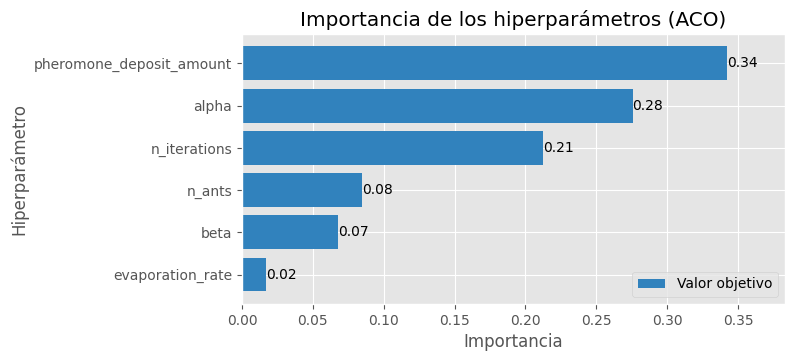

In [16]:
# --- Ejecutar la optimización con Optuna para ACO ---
random.seed(42)
np.random.seed(42)
print("--- Iniciando Optimización de Hiperparámetros para ACO con Optuna ---")
inicio = time.time()
study_aco = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study_aco.optimize(objective_aco, n_trials=30, timeout=300) # n_trials bajo para demo
print(f"\nOptimización ACO completada en {time.time() - inicio:.1f} s ({len(study_aco.trials)} pruebas).")
print("Mejor valor (longitud de tour):", round(study_aco.best_value, 2))
print("Mejores hiperparámetros para ACO:", study_aco.best_params)

ax = optuna.visualization.matplotlib.plot_param_importances(study_aco)
traducir_grafica(ax, "Importancia de los hiperparámetros (ACO)", "Importancia", "Hiperparámetro")
ax.figure.set_size_inches(7, 3.5)
plt.show()

La colonia de hormigas también alcanza el mismo recorrido en casi todas las pruebas, desde la primera, así que la importancia de los hiperparámetros tiene aquí el mismo valor limitado que en el recocido simulado.

## GRASP

GRASP alterna dos fases en cada iteración. La construcción parte de una ciudad al azar y, en cada paso, forma la lista restringida de candidatos (RCL, *restricted candidate list*) con las ciudades no visitadas cuya distancia a la ciudad actual no supera

$$
c_{\min} + \alpha_{\text{RCL}}\,(c_{\max} - c_{\min}),
$$

donde $c_{\min}$ y $c_{\max}$ son la menor y la mayor distancia entre los candidatos; la siguiente ciudad se elige al azar dentro de la RCL. Con $\alpha_{\text{RCL}} = 0$ la construcción es voraz y con $\alpha_{\text{RCL}} = 1$ es aleatoria entre todos los candidatos. La segunda fase es una búsqueda local 2-opt de primera mejora, que invierte el segmento entre dos posiciones, acepta el primer cambio que acorta el recorrido, vuelve a empezar desde el recorrido nuevo y se detiene cuando ningún cambio mejora o cuando alcanza el número máximo de mejoras permitido. GRASP devuelve el mejor recorrido de todas las iteraciones.

In [17]:
def greedy_randomized_construction_grasp(alpha_rcl, num_cities, distance_matrix, seed=None):
    """Fase de construcción de GRASP."""
    if seed is not None:
        random.seed(seed)

    current_city = random.randint(0, num_cities - 1)
    tour = [current_city]
    visited = {current_city}

    while len(tour) < num_cities:
        candidates = []
        for next_city_candidate in range(num_cities):
            if next_city_candidate not in visited:
                cost = distance_matrix[current_city, next_city_candidate]
                candidates.append((cost, next_city_candidate))

        if not candidates: break # No más ciudades

        candidates.sort() # Ordenar por costo (greedy)

        # Crear la Restricted Candidate List (RCL)
        min_cost = candidates[0][0]
        max_cost_rcl = min_cost + alpha_rcl * (candidates[-1][0] - min_cost) if len(candidates) > 1 and candidates[-1][0] > min_cost else min_cost

        rcl = [c for c_cost, c in candidates if c_cost <= max_cost_rcl]
        if not rcl: # Si RCL está vacía (e.g., alpha_rcl=0 y hay empates), tomar el mejor
            rcl = [candidates[0][1]]

        chosen_city = random.choice(rcl)[1] if isinstance(rcl[0], tuple) else random.choice(rcl)


        tour.append(chosen_city)
        visited.add(chosen_city)
        current_city = chosen_city

    return tour

def local_search_2opt_grasp(tour, distance_matrix, max_improvements=10):
    """Búsqueda local simple (2-opt) para GRASP."""
    current_tour = tour[:]
    current_length = calculate_tour_length(current_tour, distance_matrix)
    num_cities = len(current_tour)
    improved = True
    improvements_count = 0

    while improved and improvements_count < max_improvements:
        improved = False
        for i in range(num_cities -1): # No necesitamos num_cities -1 para el último arco con el primero
            for j in range(i + 1, num_cities):
                # Realizar un intercambio 2-opt
                # El tour es A -> B ... C -> D
                # Nuevo tour A -> C ... B -> D (segmento B...C invertido)
                # A = tour[i], B = tour[(i+1)%num_cities] (si i es el último, B es el primero)
                # C = tour[j], D = tour[(j+1)%num_cities]

                # Simplificación: intercambiar arcos (i, i+1) y (j, j+1)
                # por (i, j) y (i+1, j+1) no es 2-opt estándar.
                # 2-opt: invertir el segmento entre tour[i+1] y tour[j]

                if j == i + 1: continue # Arcos adyacentes, no hay segmento para invertir

                new_tour = current_tour[:]
                segment_to_reverse = new_tour[i+1 : j+1]
                segment_to_reverse.reverse()
                new_tour[i+1 : j+1] = segment_to_reverse

                new_length = calculate_tour_length(new_tour, distance_matrix)

                if new_length < current_length:
                    current_tour = new_tour[:]
                    current_length = new_length
                    improved = True
                    improvements_count += 1
                    break # Reiniciar búsqueda desde el nuevo tour (estrategia de primera mejora)
            if improved:
                break
    return current_tour, current_length


def run_grasp_tsp(n_grasp_iterations, rcl_alpha, local_search_max_improvements, seed=None):
    """Ejecuta GRASP para el TSP."""
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    num_cities = NUM_CITIES_GLOBAL
    best_tour_overall = None
    best_tour_length_overall = float('inf')

    for _ in range(int(n_grasp_iterations)):
        # Fase de Construcción
        constructed_tour = greedy_randomized_construction_grasp(rcl_alpha, num_cities, DISTANCE_MATRIX_GLOBAL, seed=None) # Nueva semilla para cada construcción

        # Fase de Búsqueda Local
        improved_tour, improved_length = local_search_2opt_grasp(constructed_tour, DISTANCE_MATRIX_GLOBAL, int(local_search_max_improvements))

        if improved_length < best_tour_length_overall:
            best_tour_length_overall = improved_length
            best_tour_overall = improved_tour[:]

    return best_tour_length_overall, best_tour_overall

### Espacio de búsqueda y estudio

| Hiperparámetro | Rango | Paso |
|---|---|---|
| `n_grasp_iterations` | 10 a 100 | 10 |
| `rcl_alpha` | 0 a 0,5 | 0,05 |
| `local_search_max_improvements` | 5 a 20 | 1 |

Se hacen 50 pruebas.

In [18]:
def objective_grasp(trial):
    """Función objetivo para Optuna para optimizar los hiperparámetros de GRASP."""
    n_grasp_iterations = trial.suggest_int("n_grasp_iterations", 10, 100, step=10)
    # alpha para RCL: 0 es puramente greedy, 1 es puramente aleatorio (entre los candidatos)
    rcl_alpha = trial.suggest_float("rcl_alpha", 0.0, 0.5, step=0.05)
    local_search_max_improvements = trial.suggest_int("local_search_max_improvements", 5, 20, step=1)


    best_fitness, _ = run_grasp_tsp(n_grasp_iterations, rcl_alpha, local_search_max_improvements, seed=123)
    return best_fitness if best_fitness is not None else float('inf')

--- Iniciando Optimización de Hiperparámetros para GRASP con Optuna ---



Optimización GRASP completada en 5.7 s (50 pruebas).
Mejor valor (longitud de tour): 352.32
Mejores hiperparámetros para GRASP: {'n_grasp_iterations': 40, 'rcl_alpha': 0.5, 'local_search_max_improvements': 16}


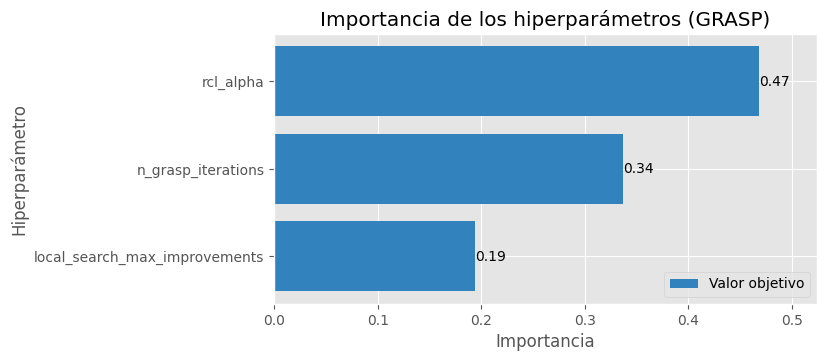

In [19]:
# --- Ejecutar la optimización con Optuna para GRASP ---
random.seed(42)
np.random.seed(42)
print("--- Iniciando Optimización de Hiperparámetros para GRASP con Optuna ---")
inicio = time.time()
study_grasp = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study_grasp.optimize(objective_grasp, n_trials=50, timeout=300) # n_trials bajo para demo
print(f"\nOptimización GRASP completada en {time.time() - inicio:.1f} s ({len(study_grasp.trials)} pruebas).")
print("Mejor valor (longitud de tour):", round(study_grasp.best_value, 2))
print("Mejores hiperparámetros para GRASP:", study_grasp.best_params)

ax = optuna.visualization.matplotlib.plot_param_importances(study_grasp)
traducir_grafica(ax, "Importancia de los hiperparámetros (GRASP)", "Importancia", "Hiperparámetro")
ax.figure.set_size_inches(7, 3.5)
plt.show()

Con GRASP ocurre lo mismo. La mayoría de las pruebas llega al mismo recorrido desde la primera, y la importancia estimada se apoya en las pocas que no lo hacen.

## Los cuatro estudios lado a lado

La tabla reúne, para cada metaheurística, el mejor valor encontrado, la primera prueba que lo alcanzó, cuántas pruebas llegaron a ese mismo valor (con una tolerancia numérica, porque dos recorridos iguales pueden diferir en el último decimal al sumarse en otro orden) y la mediana de todas las pruebas.

In [20]:
import pandas as pd

filas = []
for nombre, estudio in [("GA", study_ga), ("SA", study_sa), ("ACO", study_aco), ("GRASP", study_grasp)]:
    completas = [t for t in estudio.trials if t.value is not None]
    valores = np.array([t.value for t in completas])
    primera = min(t.number for t in completas if np.isclose(t.value, estudio.best_value))
    filas.append({"Metaheurística": nombre,
                  "Pruebas": len(valores),
                  "Mejor longitud": round(estudio.best_value, 2),
                  "Primera prueba que lo alcanza": primera,
                  "Pruebas que alcanzan el mejor": int(np.sum(np.isclose(valores, estudio.best_value))),
                  "Mediana de las pruebas": round(float(np.median(valores)), 2)})
pd.DataFrame(filas).set_index("Metaheurística")

,Pruebas,Mejor longitud,Primera prueba que lo alcanza,Pruebas que alcanzan el mejor,Mediana de las pruebas
Metaheurística,,,,,
GA,50,352.32,5,19,360.81
SA,30,352.32,0,26,352.32
ACO,30,352.32,0,28,352.32
GRASP,50,352.32,0,41,352.32


Las cuatro metaheurísticas llegan a la misma longitud mínima, y en el recocido simulado, la colonia de hormigas y GRASP la mediana de las pruebas coincide con ese mínimo. Con 20 ciudades la instancia resulta demasiado fácil para distinguir unas configuraciones de otras, salvo en el algoritmo genético, cuyas pruebas sí varían. Para que el ajuste aporte información hace falta un problema que discrimine, con instancias más grandes o varias instancias a la vez; evaluar cada configuración con varias semillas, para no premiar una corrida afortunada, y, cuando hay empates, tener en cuenta también el tiempo de cómputo. El capítulo 10 retoma la pregunta de cómo comparar algoritmos estocásticos con varias corridas.